# Extended ALiBi accuracy campaign

**Purpose:** push the variational transformer substantially beyond the short
pilots before starting the projector method. These are the same disorder-ID-0
Kagome Hamiltonians at Γ=0.5,h=0.3, for N=192,108,48,12 spins, with two
independent training branches each. The notebook reads downloaded artifacts;
its status cell explicitly distinguishes ongoing work from completed results.

| Setting | Previous larger-size refinement | Extended campaign |
|---|---:|---:|
| Hidden width | 32 | 64 |
| Causal ALiBi blocks | 2 | 4 |
| Attention heads | 4 | 4 |
| Main VMC updates | 2,400 | 8,000 |
| Main sample batch | 128 | 512 |
| Further low-rate updates | 0 | 4,000 |
| Low-rate sample batch | — | 1,024 |
| Independent branches per size | 2 | 2 |

The expanded model first learns the parent model's conditional probabilities
from teacher-sampled configurations (1,000 updates). This is initialization,
not a physical target. Subsequent VMC minimizes the physical energy without
exact ground-state labels. Larger batches and a low-learning-rate stage are
intended to reduce optimization noise; added capacity is a hypothesis to test.

Every 1,000 updates, independent interim energy samples assess a candidate.
Each stage's lowest validation-energy candidate is retained. The parent also
remains eligible. All three candidates receive independent final evaluations
(16,384 energy samples plus four-replica observable samples per candidate).
No candidate selection uses these final measurements. At N=12, enumeration
provides deterministic errors and fidelity as additional validation.

**Interpretation:** lowering energy and variance is evidence of improvement,
not proof of an exact ground state. Compare stage, capacity, seed, and observable
sensitivity. No projector runs in this campaign. Completing its scheduled
budget does not prove the limit of transformer accuracy has been reached.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT=Path.cwd()
if not (ROOT/'code/transformer_qmc').exists():
    ROOT=ROOT.parent
RESULTS=ROOT/'data/kagome/transformer_af_alibi_accuracy_v1'
status=json.loads((RESULTS/'status.json').read_text()) if (RESULTS/'status.json').exists() else {'state':'not downloaded'}
summary=json.loads((RESULTS/'summary.json').read_text()) if (RESULTS/'summary.json').exists() else []
display(Markdown(f"**Downloaded state:** `{status}`\n\n**Completed branches:** {len(summary)}/8."))
table=['| Spins | Seed | Stage | Last saved step | E/N in last training report |', '|---:|---:|---|---:|---:|']
for directory in sorted(RESULTS.glob('alibi__*')):
    settings=json.loads((directory/'settings.json').read_text())
    for stage in ('vmc','polish'):
        path=directory/f'{stage}_history.json'
        if path.exists():
            rows=json.loads(path.read_text())
            if rows:
                last=rows[-1]
                table.append(f"| {settings['N']} | {settings['task']['seed']} | {stage} | {last['step']} | {last['energy']/settings['N']:.7f} |")
display(Markdown('\n'.join(table)))
display(Markdown('Training energies are noisy progress indicators. Use independent validation/final measurements below to assess improvements.'))


**Downloaded state:** `{'state': 'stopped_for_shared_checkpoint_requirement', 'task': {'L': 8, 'seed': 302, 'parent': '/root/autodl-tmp/transformer-af-ltfim-20261026-alibi-sizes-v1/results/alibi__L08__N192__g0p5__h0p3__dis000__init-shared__seed202/alibi__L08__N192__g0p5__h0p3__dis000__init-shared__seed202__step002400__final.pt', 'parent_sha256': 'f16a331d423a3e916d1a32797390a2498e0dc24e14c9f0f1d618021b0b39f47e'}, 'stage': 'polish', 'completed': 1, 'reason': 'User requires one set of trained weights across sizes; preserved latest resumable specialist checkpoints.'}`

**Completed branches:** 1/8.

| Spins | Seed | Stage | Last saved step | E/N in last training report |
|---:|---:|---|---:|---:|
| 192 | 301 | vmc | 8000 | -1.0930179 |
| 192 | 301 | polish | 4000 | -1.0932199 |
| 192 | 302 | vmc | 8000 | -1.0941661 |
| 192 | 302 | polish | 600 | -1.0938806 |

Training energies are noisy progress indicators. Use independent validation/final measurements below to assess improvements.

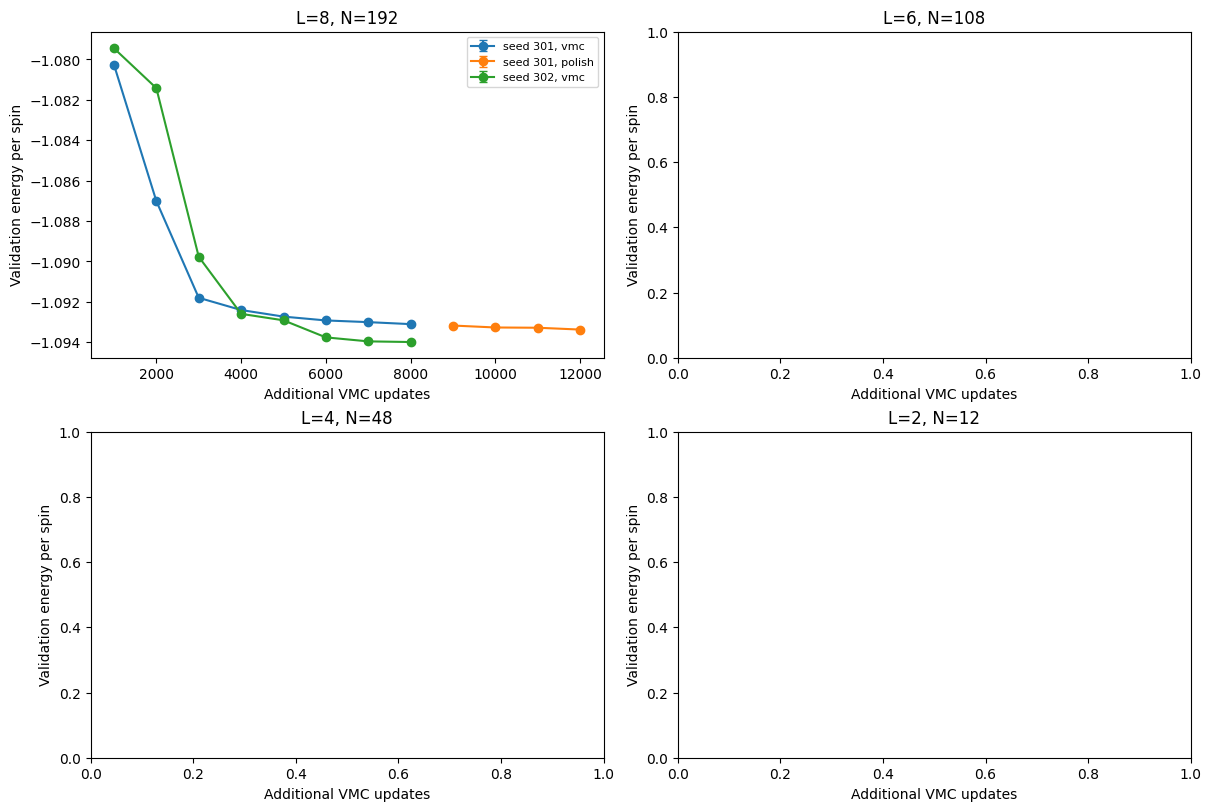

In [2]:
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
plotted=False
for ax,L in zip(axes.flat,(8,6,4,2)):
    for directory in sorted(RESULTS.glob(f'alibi__L{L:02d}__*')):
        settings=json.loads((directory/'settings.json').read_text())
        for stage,offset in [('vmc',0),('polish',8000)]:
            path=directory/f'{stage}_validation.json'
            if path.exists():
                values=json.loads(path.read_text())
                ax.errorbar([v['step']+offset for v in values],[v['mean']/(3*L*L) for v in values],
                            yerr=[v['se']/(3*L*L) for v in values],marker='o',capsize=3,
                            label=f"seed {settings['task']['seed']}, {stage}")
                plotted=True
    ax.set(title=f'L={L}, N={3*L*L}',xlabel='Additional VMC updates',ylabel='Validation energy per spin')
    if ax.lines:
        ax.legend(fontsize=8)
if plotted:
    fig.savefig(RESULTS/'extended_alibi_energy.png',dpi=180)
    fig.savefig(RESULTS/'extended_alibi_energy.pdf')
    plt.show()
else:
    plt.close(fig)
    display(Markdown('Independent validation curves will appear after the first 1,000 VMC updates.'))


In [3]:
if summary:
    table=['| Spins | Seed | Candidate | E/N ± SE | Variance/N | q² ± SE | Connected χ ± SE |',
           '|---:|---:|---|---:|---:|---:|---:|']
    for run in summary:
        n=run['N']
        for stage in ('parent','vmc','polish'):
            r=run['reports'][stage]['sampled']
            def estimate(key,scale=1):
                return f"{r[key]['mean']/scale:.7f} ± {r[key]['se']/scale:.7f}"
            label=stage+(' (selected by interim energy)' if stage==run['selected_stage'] else '')
            table.append(f"| {n} | {run['seed']} | {label} | {estimate('energy',n)} | {r['local_energy_variance']/n:.6g} | {estimate('q2')} | {estimate('chi_connected')} |")
    display(Markdown('### Independent final evaluation\n\n'+'\n'.join(table)))
else:
    display(Markdown('**Final evaluations pending.** No accuracy improvement is claimed before these are available.'))


### Independent final evaluation

| Spins | Seed | Candidate | E/N ± SE | Variance/N | q² ± SE | Connected χ ± SE |
|---:|---:|---|---:|---:|---:|---:|
| 192 | 301 | parent | -1.0693782 ± 0.0000805 | 0.0188619 | 0.4803714 ± 0.0004796 | 0.2270775 ± 0.0025023 |
| 192 | 301 | vmc | -1.0930411 ± 0.0000296 | 0.00335483 | 0.4457850 ± 0.0006133 | 0.3105723 ± 0.0030728 |
| 192 | 301 | polish (selected by interim energy) | -1.0933367 ± 0.0000271 | 0.00306754 | 0.4702874 ± 0.0005412 | 0.2218348 ± 0.0026218 |

In [4]:
if summary:
    lines=['| Spins | Seed | Selected − parent E/N ± combined SE | Selected − parent q² ± combined SE |',
           '|---:|---:|---:|---:|']
    for run in summary:
        parent=run['reports']['parent']['sampled']
        candidate=run['reports'][run['selected_stage']]['sampled']
        if run['selected_stage']=='parent':
            lines.append(f"| {run['N']} | {run['seed']} | Parent retained | Parent retained |")
            continue
        cells=[]
        for key,scale in [('energy',run['N']),('q2',1)]:
            delta=(candidate[key]['mean']-parent[key]['mean'])/scale
            se=np.hypot(candidate[key]['se'],parent[key]['se'])/scale
            cells.append(f'{delta:.7f} ± {se:.7f}')
        lines.append(f"| {run['N']} | {run['seed']} | "+' | '.join(cells)+' |')
    display(Markdown('\n'.join(lines)))
    for run in summary:
        if run['L']==2:
            display(Markdown(f"**N=12, seed {run['seed']}:**"))
            for stage in ('parent','vmc','polish'):
                d=run['reports'][stage]['exact_diagnostics']
                display(Markdown(f"{stage}: energy error/spin {d['energy_error_per_spin']:.3g}, q² relative error {d['q2_relative_error']:.3g}, connected-χ relative error {d['chi_connected_relative_error']:.3g}, fidelity {d['fidelity']:.9f}."))


| Spins | Seed | Selected − parent E/N ± combined SE | Selected − parent q² ± combined SE |
|---:|---:|---:|---:|
| 192 | 301 | -0.0239584 ± 0.0000849 | -0.0100840 ± 0.0007231 |

## Decision before projection

Review the last validation windows for residual energy improvement, compare
the main and low-rate stages on independent samples, and inspect both seeds'
observables. Distinguish a change smaller than measurement uncertainty from a
demonstrated plateau. A large seed difference in q² or connected χ remains an
unresolved variational issue even if energies agree.

All parent and candidate checkpoint paths, SHA-256 hashes, and evaluation RNG
seeds are retained. The parent can be retained if expanded training fails to
improve it. Any further optimization changes produce new checkpoint identities.
The next projector stage starts only after reviewing this evidence; this
notebook does not launch it automatically.
